Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Regression Model Comparison
               Model            MSE  R² Score
0  Linear Regression  549007.004835  0.178625
1      Decision Tree  611416.906792  0.085253
2      Random Forest  598415.214132  0.104705


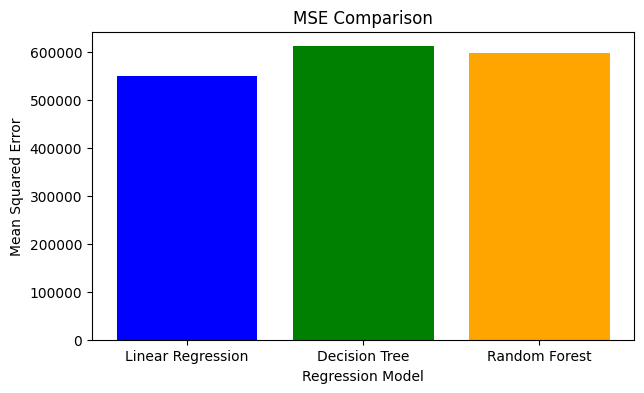

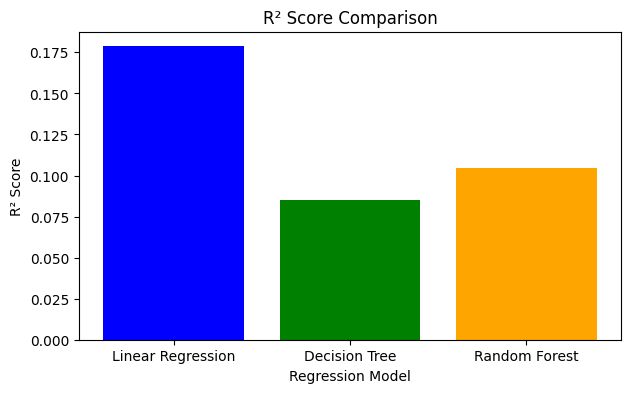

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
from google.colab import drive

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_squared_error, r2_score

# Mount Google Drive
drive.mount('/content/drive')

# Load dataset
df = pd.read_csv('/content/drive/MyDrive/Colab Notebooks/PBA PRACTICAL FILE/superstore.csv')

# Features and target
X = df[['Ship Mode', 'Segment', 'Region', 'Category', 'Sub-Category']]
y = df['Sales']

# Convert categorical data into numbers
X = pd.get_dummies(X, drop_first=True)

# Split data
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

# Models
models = {
    'Linear Regression': LinearRegression(),
    'Decision Tree': DecisionTreeRegressor(random_state=42),
    'Random Forest': RandomForestRegressor(
        n_estimators=100,
        random_state=42
    )
}

# Train and evaluate models
results = []
for name, model in models.items():

    model.fit(X_train, y_train)

    pred = model.predict(X_test)

    mse = mean_squared_error(y_test, pred)
    r2 = r2_score(y_test, pred)

    results.append([name, mse, r2])

# Display results
results = pd.DataFrame(
    results,
    columns=['Model', 'MSE', 'R² Score'])
print("Regression Model Comparison")
print(results)

# MSE Comparison
plt.figure(figsize=(7, 4))

plt.bar(
    results['Model'],
    results['MSE'],
    color=['blue', 'green', 'orange']
)

plt.title('MSE Comparison')
plt.xlabel('Regression Model')
plt.ylabel('Mean Squared Error')
plt.xticks(rotation=0)
plt.show()

# R² Score Comparison
plt.figure(figsize=(7, 4))

plt.bar(
    results['Model'],
    results['R² Score'],
    color=['blue', 'green', 'orange']
)

plt.title('R² Score Comparison')
plt.xlabel('Regression Model')
plt.ylabel('R² Score')
plt.xticks(rotation=0)
plt.show()